## Week 4 Lab Session Worksheet: Fundamental Visualisation Forms
This notebook contains activities and exercises for analysing and visualising the `Car_Sales.csv` dataset using pandas, matplotlib, numpy and seaborn.

This lab session covers visualising different data types using `Car_Sales.csv` dataset. 

## Importatnt 

You need to replace `Car_Sales.csv` in the same folder as `Week_4_Lab_Session_Worksheet`

**Note:** 

Always save your visualisations:

`plt.savefig('plot_name.png', dpi=300, bbox_inches='tight')`

For better readability, format large numbers

`plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'£{int(x):,}'))`


Handle missing values

Check for missing values

`print(df.isnull().sum())`

Handle missing values if needed

`df = df.dropna()  # or df.fillna(method='ffill')`



In [2]:
# First, let's import the necessary libraries and load the data.
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set Seaborn style directly
sns.set_style("whitegrid")

# Read the dataset
df = pd.read_csv('Car_Sales.csv')

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

## Exercise 1: Monthly Sales Analysis

**Objective:** Create a line plot showing total monthly sales across all makes


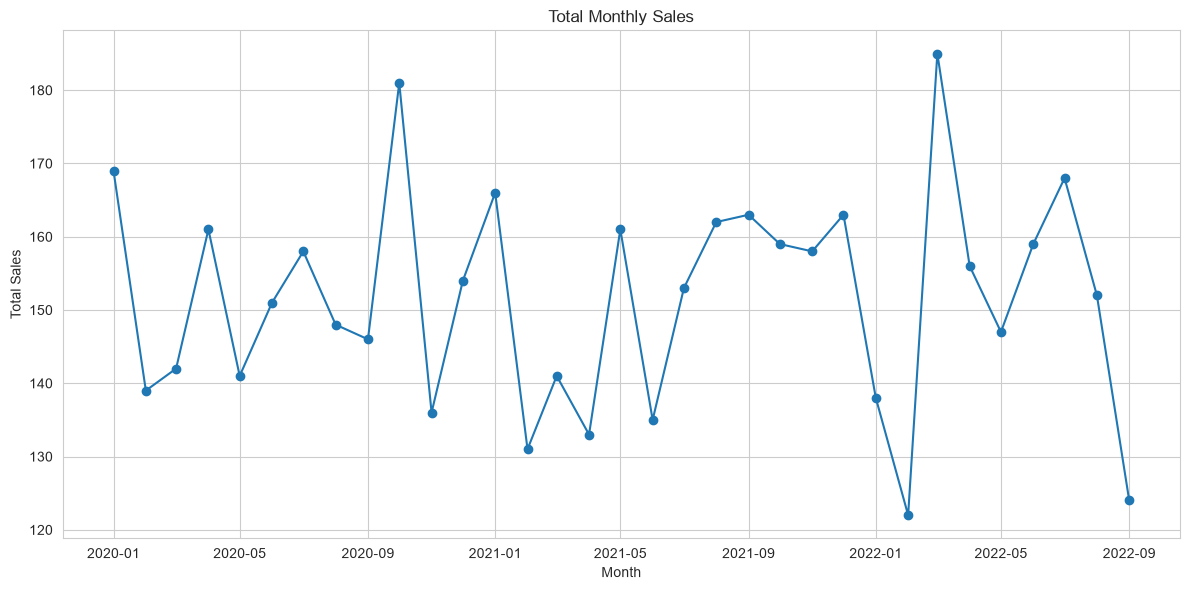

In [3]:
#Start your solution

# Group sales by month
monthly_sales = (
    df.groupby(df['date'].dt.to_period('M'))['sales']
    .sum()
)

# Convert the month index to timestamps for plotting
monthly_sales.index = monthly_sales.index.to_timestamp()

# Create the line plot
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Total Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.grid(True)

plt.tight_layout()

# Save the visualisation
plt.savefig(
    'monthly_sales.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## Exercise 2: Car Type Distribution

**Objective:** Create a pie chart showing the distribution of car types

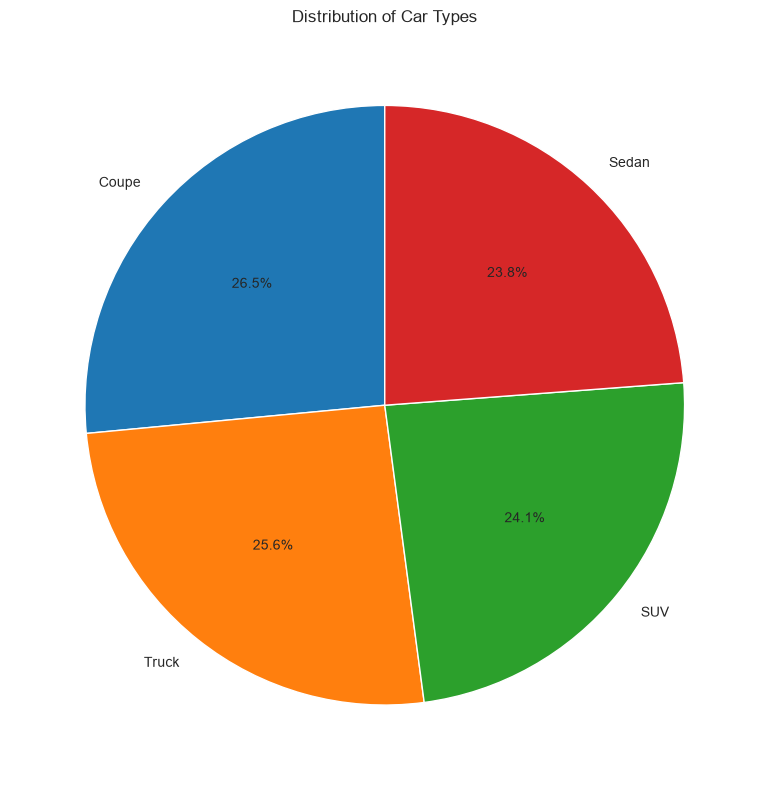

In [4]:
#Start your solution

# Count how many cars there are for each type
car_type_counts = df['type'].value_counts()

# Create the figure
plt.figure(figsize=(8, 8))

# Create the pie chart
plt.pie(
    car_type_counts.values,
    labels=car_type_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

# Add a title
plt.title('Distribution of Car Types')

# Make the layout fit properly
plt.tight_layout()

# Save the chart
plt.savefig(
    'car_type_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

# Show the chart
plt.show()

## Exercise 3: Price Range Analysis

**Objective:** Create a histogram showing price distribution with different bins

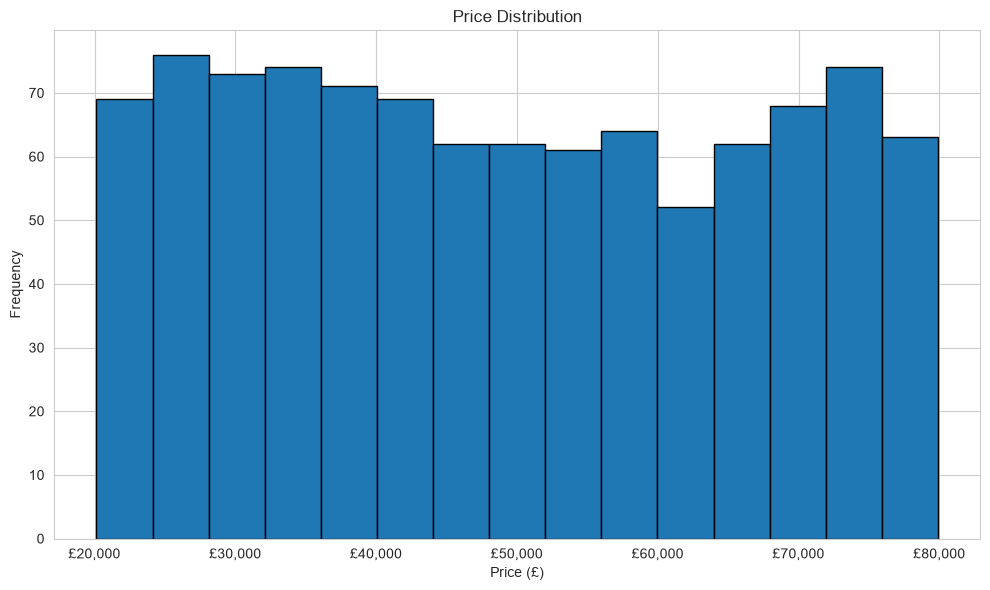

In [6]:
# Exercise 3: Price Range Analysis

from matplotlib.ticker import StrMethodFormatter

# Create the figure
plt.figure(figsize=(10, 6))

# Plot the price distribution
plt.hist(
    df['price'],
    bins=15,
    edgecolor='black'
)

# Add labels and title
plt.title('Price Distribution')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')

# Format the x-axis as currency
plt.gca().xaxis.set_major_formatter(
    StrMethodFormatter('£{x:,.0f}')
)

plt.tight_layout()

# Save the chart
plt.savefig(
    'price_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

# Show the chart
plt.show()

## Exercise 4: Make Comparison

**Objective:** Create a box plot comparing prices across different makes

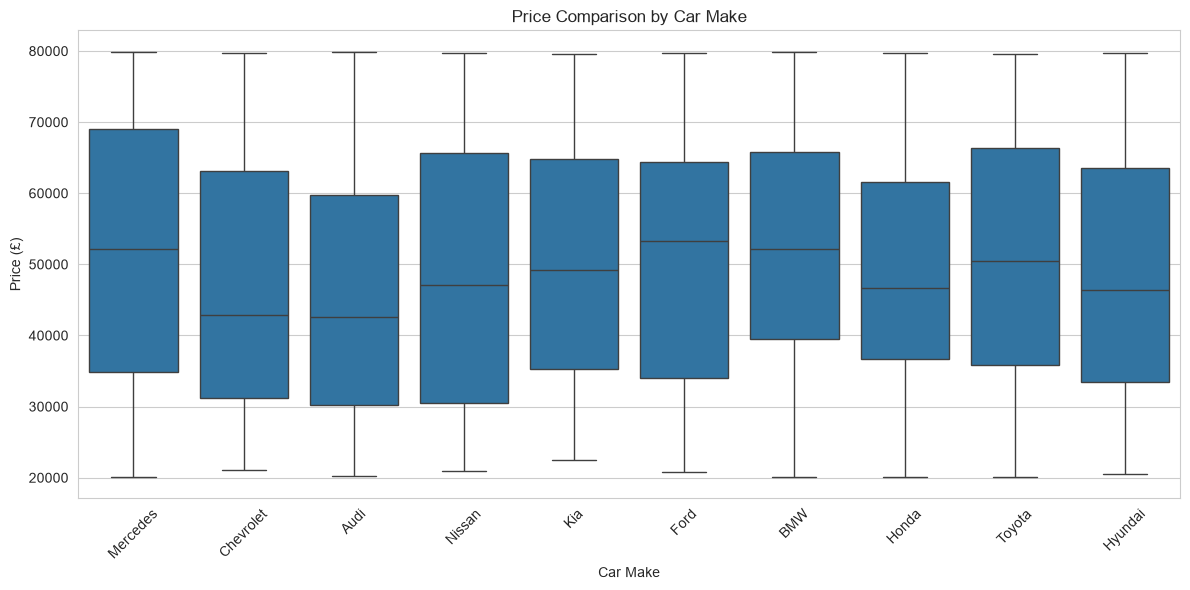

In [7]:
#Start your solution

# Create the figure
plt.figure(figsize=(12, 6))

# Create a box plot of prices for each car make
sns.boxplot(
    data=df,
    x='make',
    y='price'
)

# Add labels and title
plt.title('Price Comparison by Car Make')
plt.xlabel('Car Make')
plt.ylabel('Price (£)')

# Rotate the make names so they are easier to read
plt.xticks(rotation=45)

plt.tight_layout()

# Save the chart
plt.savefig(
    'price_by_make.png',
    dpi=300,
    bbox_inches='tight'
)

# Show the chart
plt.show()

## Exercise 5: Sales vs MPG Relationship

**Objective:** Create a scatter plot showing the relationship between sales and MPG

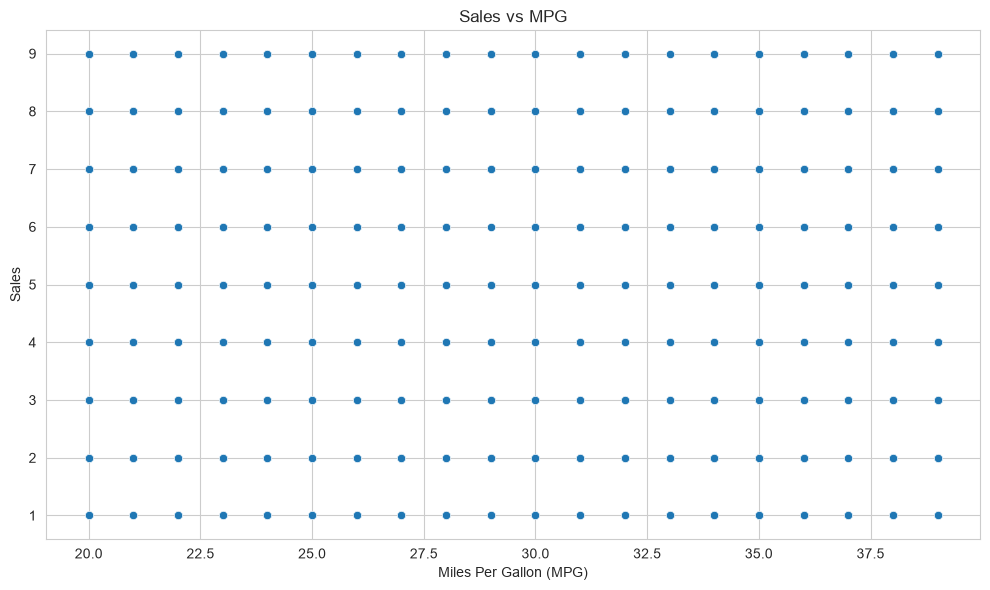

In [8]:
#Start your solution

# Create the figure
plt.figure(figsize=(10, 6))

# Plot sales against MPG
sns.scatterplot(
    data=df,
    x='mpg',
    y='sales'
)

# Add labels and title
plt.title('Sales vs MPG')
plt.xlabel('Miles Per Gallon (MPG)')
plt.ylabel('Sales')

plt.tight_layout()

# Save the chart
plt.savefig(
    'sales_vs_mpg.png',
    dpi=300,
    bbox_inches='tight'
)

# Show the chart
plt.show()

## Exercise 6: Monthly Average Price Trends

**Objective:** Create a line plot showing average monthly prices with confidence intervals.

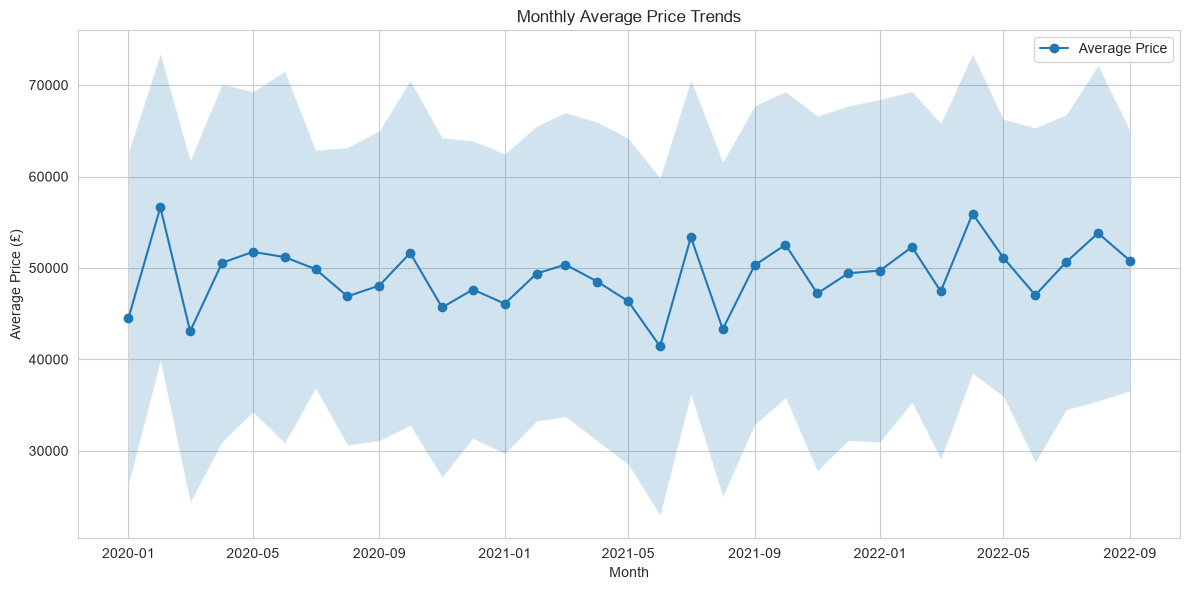

In [9]:
#Start your solution


# Exercise 6: Monthly Average Price Trends

# Create a month column from the date
df['month'] = df['date'].dt.to_period('M')

# Calculate average price and standard deviation for each month
monthly_price = df.groupby('month')['price'].agg(['mean', 'std'])

# Convert month values to timestamps so they plot properly
monthly_price.index = monthly_price.index.to_timestamp()

# Create the figure
plt.figure(figsize=(12, 6))

# Plot the monthly average price
plt.plot(
    monthly_price.index,
    monthly_price['mean'],
    marker='o',
    label='Average Price'
)

# Add the confidence area around the average
plt.fill_between(
    monthly_price.index,
    monthly_price['mean'] - monthly_price['std'],
    monthly_price['mean'] + monthly_price['std'],
    alpha=0.2
)

# Add labels and title
plt.title('Monthly Average Price Trends')
plt.xlabel('Month')
plt.ylabel('Average Price (£)')

plt.legend()
plt.tight_layout()

# Save the chart
plt.savefig(
    'monthly_average_price.png',
    dpi=300,
    bbox_inches='tight'
)

# Show the chart
plt.show()

## Exercise 7: Type-wise MPG Comparison

**Objective:** Create a violin plot comparing MPG across different car types

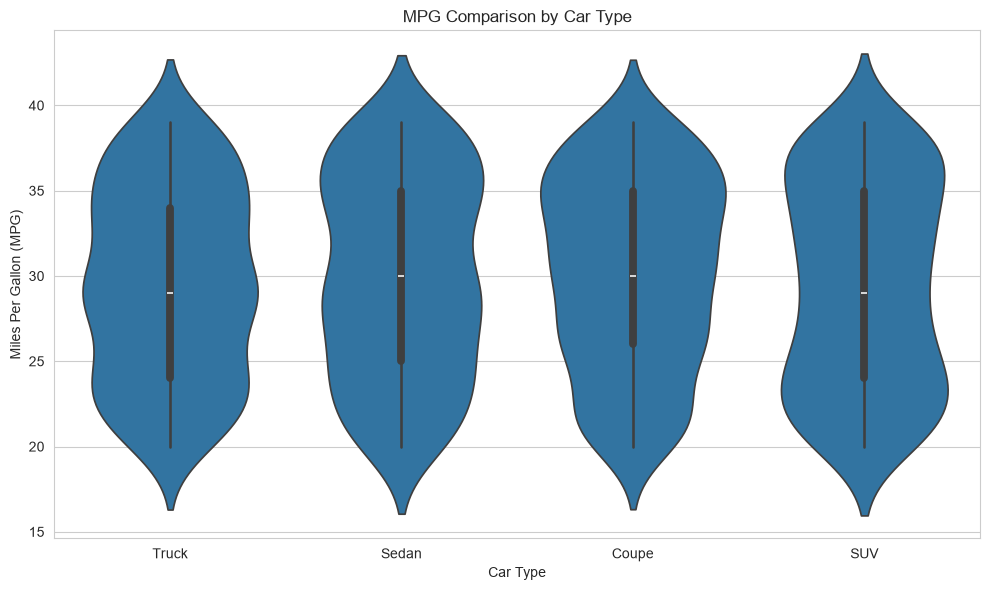

In [ ]:
#Start your solution

plt.figure(figsize=(10, 6))

# Compare MPG distributions for each car type
sns.violinplot(
    data=df,
    x='type',
    y='mpg'
)

# Add labels and title
plt.title('MPG Comparison by Car Type')
plt.xlabel('Car Type')
plt.ylabel('Miles Per Gallon (MPG)')

plt.tight_layout()

# Save the chart
plt.savefig(
    'mpg_by_type.png',
    dpi=300,
    bbox_inches='tight'
)

# Show the chart
plt.show()

## Exercise 8: Make Market Share Analysis

**Objective:** Create a stacked bar chart showing market share evolution

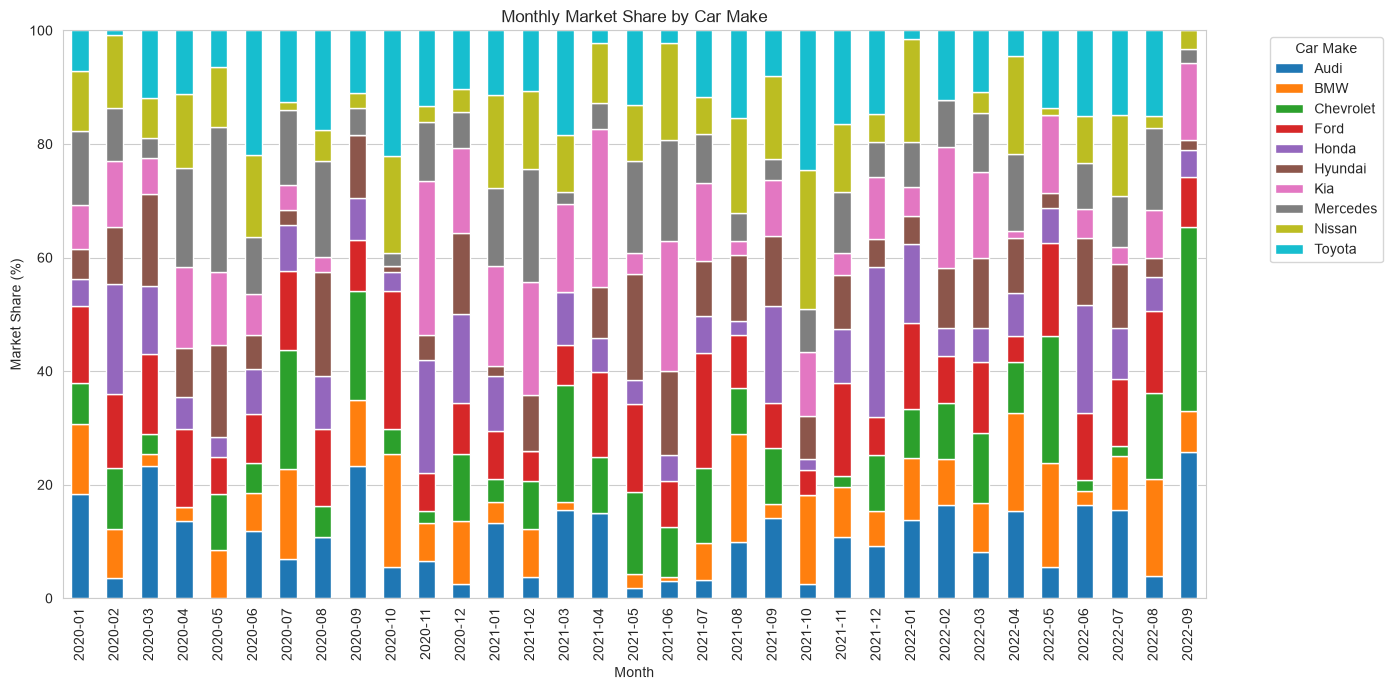

In [11]:
#Start your solution

# Create a month column from the date
df['month'] = df['date'].dt.to_period('M')

# Get total sales for each make in each month
monthly_make_sales = (df.groupby(['month', 'make'])['sales'].sum().unstack(fill_value=0))

# Convert sales into percentages for each month
market_share = monthly_make_sales.div(
    monthly_make_sales.sum(axis=1),
    axis=0
) * 100

# Plot the market share as a stacked bar chart
market_share.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

# Add labels and title
plt.title('Monthly Market Share by Car Make')
plt.xlabel('Month')
plt.ylabel('Market Share (%)')

# Move the legend outside so the chart is easier to read
plt.legend(
    title='Car Make',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()

# Save the chart
plt.savefig(
    'market_share_by_make.png',
    dpi=300,
    bbox_inches='tight'
)

# Show the chart
plt.show()

## Exercise 9: Multi-variable Analysis

**Objective:** Create a faceted scatter plot showing price vs MPG for each car type.

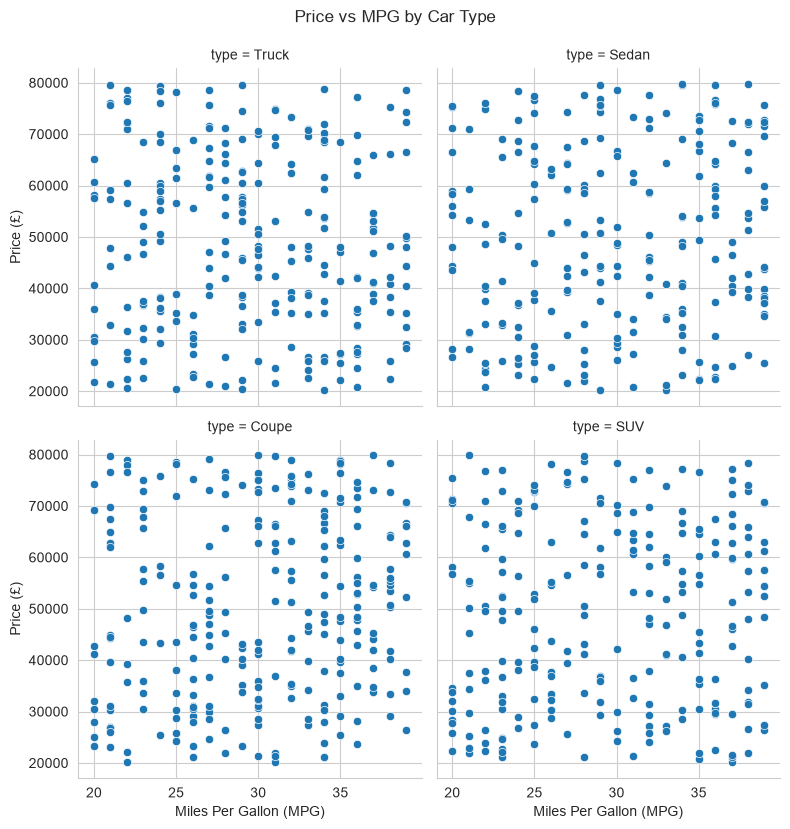

In [12]:
#Start your solution
# Create separate scatter plots for each car type
plot = sns.relplot(
    data=df,
    x='mpg',
    y='price',
    col='type',
    kind='scatter',
    col_wrap=2,
    height=4
)

# Add a title for the whole figure
plot.fig.suptitle(
    'Price vs MPG by Car Type',
    y=1.03
)

# Set axis labels
plot.set_axis_labels(
    'Miles Per Gallon (MPG)',
    'Price (£)'
)

# Save the chart
plot.savefig(
    'price_vs_mpg_by_type.png',
    dpi=300,
    bbox_inches='tight'
)

# Show the chart
plt.show()

In [11]:
#Start your solution